# Decision Trees: Complete Guide

Decision Trees are non-parametric supervised learning methods used for classification and regression.

## Topics Covered:
1. **What is a Decision Tree?** - Core concepts and intuition
2. **Terminology** - Root node, internal nodes, leaf nodes
3. **Splitting Criteria** - Gini impurity, Entropy, Information Gain
4. **Building a Decision Tree** - Recursive partitioning
5. **Decision Tree for Classification** - Complete example
6. **Decision Tree for Regression** - Complete example
7. **Pruning** - Preventing overfitting
8. **Feature Importance** - Understanding feature contributions
9. **Visualization** - Plotting and interpreting trees
10. **Advantages and Disadvantages**

## 1. Setup and Imports

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import load_iris, make_classification
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 2. What is a Decision Tree?

### Definition
A Decision Tree is a flowchart-like tree structure where:
- **Internal nodes** represent feature tests (e.g., `age > 30?`)
- **Branches** represent the outcome of the test
- **Leaf nodes** represent the final decision (class label or value)

### Intuition
Think of a decision tree as a series of questions you ask to make a decision:

```
Is age > 30?
├── Yes → Is income > 50000?
│   ├── Yes → Buy house
│   └── No → Rent house
└── No → Is married?
    ├── Yes → Buy house
    └── No → Rent house
```

### Key Characteristics
- **Interpretable**: Easy to understand and explain
- **Non-parametric**: No assumptions about data distribution
- **Versatile**: Both classification and regression
- **Feature importance**: Built-in feature ranking

## 3. Decision Tree Terminology

### Key Terms:

1. **Root Node**: The topmost node, represents the entire dataset
2. **Internal Node**: A node that has child nodes (decision nodes)
3. **Leaf Node**: Terminal node that contains the final decision
4. **Branch**: A subset of the tree representing a possible outcome
5. **Depth**: Number of edges from root to the deepest leaf
6. **Splitting**: Dividing a node into sub-nodes
7. **Impurity**: Measure of how mixed the classes are in a node
8. **Pruning**: Removing branches to prevent overfitting

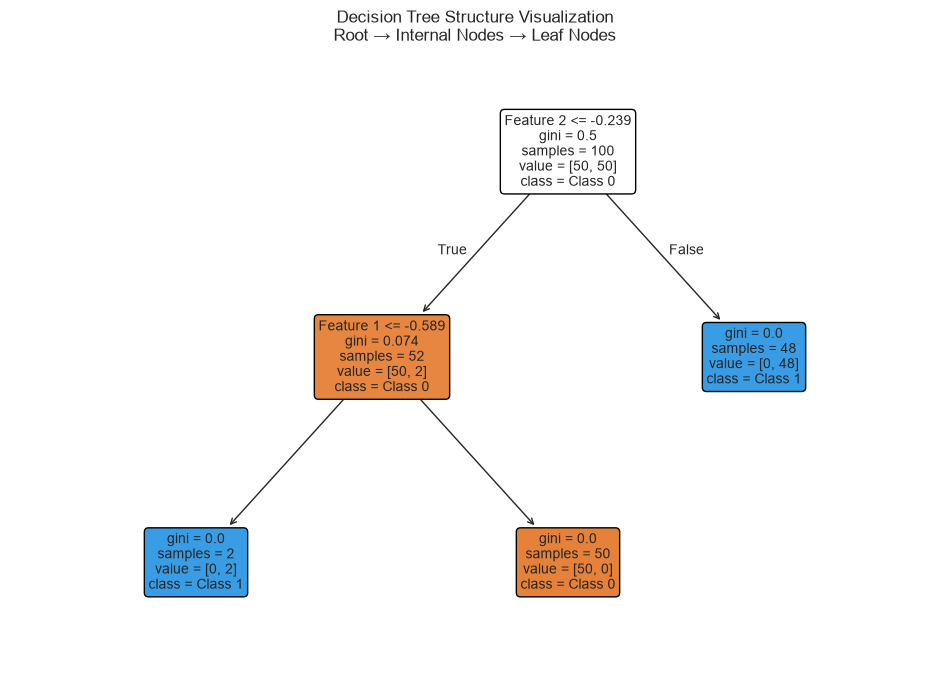

Tree Details:
Number of nodes: 5
Max depth: 2
Number of leaves: 3


In [18]:
# Visual representation of tree structure
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

# Generate simple data
X, y = make_classification(n_samples=100, n_features=2, n_informative=2, 
                           n_redundant=0, n_clusters_per_class=1, random_state=42)

# Train a shallow tree for visualization
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X, y)

# Plot the tree structure
fig, ax = plt.subplots(figsize=(12, 8))
plot_tree(tree, filled=True, rounded=True, feature_names=['Feature 1', 'Feature 2'],
          class_names=['Class 0', 'Class 1'], ax=ax, fontsize=10)
plt.title('Decision Tree Structure Visualization\nRoot → Internal Nodes → Leaf Nodes')
plt.show()

# Print tree details
print("Tree Details:")
print(f"Number of nodes: {tree.tree_.node_count}")
print(f"Max depth: {tree.tree_.max_depth}")
print(f"Number of leaves: {tree.tree_.n_leaves}")

## 4. Splitting Criteria

### 4.1 Gini Impurity

Gini impurity measures the probability of incorrect classification if we randomly label an element according to the class distribution.

$$Gini = 1 - \sum_{i=1}^{n} p_i^2$$

where $p_i$ is the proportion of class i in the node.

**Properties**:
- Range: [0, 1]
- 0 = pure node (all same class)
- Higher = more mixed
- Default for CART (Classification and Regression Trees)

=== Gini Impurity Examples ===
Pure node (all class 0): Gini = 0.0000
Pure node (all class 1): Gini = 0.0000
Even split (50-50): Gini = 0.5000
Imbalanced (75-25): Gini = 0.3750
Three classes (33-33-34): Gini = 0.6666


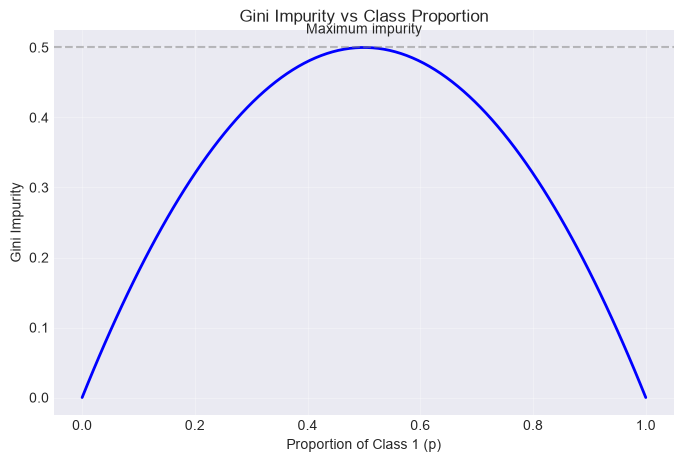

In [19]:
def gini_impurity(proportions):
    """
    Calculate Gini impurity for a node
    proportions: array of class proportions
    """
    return 1 - sum(p**2 for p in proportions)

# Example calculations
examples = {
    'Pure node (all class 0)': [1.0, 0.0],
    'Pure node (all class 1)': [0.0, 1.0],
    'Even split (50-50)': [0.5, 0.5],
    'Imbalanced (75-25)': [0.75, 0.25],
    'Three classes (33-33-34)': [0.33, 0.33, 0.34]
}

print("=== Gini Impurity Examples ===")
for label, props in examples.items():
    gini = gini_impurity(props)
    print(f"{label}: Gini = {gini:.4f}")

# Visualize Gini impurity
p = np.linspace(0, 1, 100)
gini_values = 1 - (p**2 + (1-p)**2)

plt.figure(figsize=(8, 5))
plt.plot(p, gini_values, 'b-', linewidth=2)
plt.xlabel('Proportion of Class 1 (p)')
plt.ylabel('Gini Impurity')
plt.title('Gini Impurity vs Class Proportion')
plt.grid(True, alpha=0.3)
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
plt.text(0.5, 0.52, 'Maximum impurity', ha='center')
plt.show()

### 4.2 Entropy and Information Gain

**Entropy** measures the uncertainty or randomness in a set of data.

$$Entropy = -\sum_{i=1}^{n} p_i \log_2(p_i)$$

**Information Gain** measures the reduction in entropy after splitting.

$$IG = Entropy(parent) - \sum_{i=1}^{k} \frac{n_i}{n} Entropy(child_i)$$

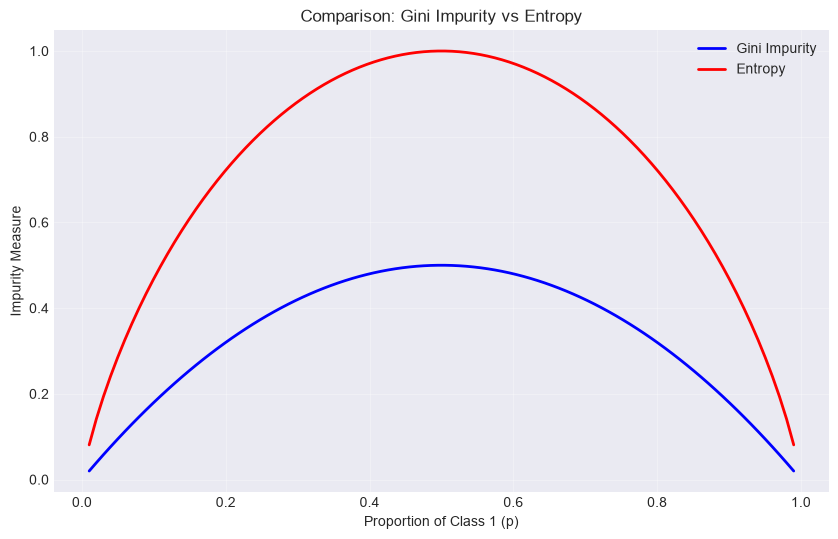

Key Differences:
1. Both measure node impurity
2. Gini is computationally faster (no log operations)
3. Entropy might produce more balanced trees
4. In practice, both often give similar results


In [20]:
def entropy(proportions):
    """Calculate entropy for a node"""
    return -sum(p * np.log2(p) for p in proportions if p > 0)

# Compare Gini and Entropy
p = np.linspace(0.01, 0.99, 100)
gini_values = 1 - (p**2 + (1-p)**2)
entropy_values = [entropy([p_i, 1-p_i]) for p_i in p]

plt.figure(figsize=(10, 6))
plt.plot(p, gini_values, 'b-', linewidth=2, label='Gini Impurity')
plt.plot(p, entropy_values, 'r-', linewidth=2, label='Entropy')
plt.xlabel('Proportion of Class 1 (p)')
plt.ylabel('Impurity Measure')
plt.title('Comparison: Gini Impurity vs Entropy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Key Differences:")
print("1. Both measure node impurity")
print("2. Gini is computationally faster (no log operations)")
print("3. Entropy might produce more balanced trees")
print("4. In practice, both often give similar results")

## 5. Building a Decision Tree Classifier

Let's build a decision tree from scratch to understand the algorithm.

In [21]:
# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

print("Iris Dataset:")
print(f"Features: {feature_names}")
print(f"Classes: {class_names}")
print(f"Number of samples: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print()

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and train decision tree classifier
dt_classifier = DecisionTreeClassifier(
    criterion='gini',  # Splitting criterion
    max_depth=3,       # Maximum depth
    min_samples_split=5,  # Minimum samples to split
    random_state=42
)
dt_classifier.fit(X_train, y_train)

# Make predictions
y_pred = dt_classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("=== Decision Tree Classifier Results ===")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

Iris Dataset:
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Number of samples: 150
Number of features: 4

=== Decision Tree Classifier Results ===
Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Visualizing the Decision Tree

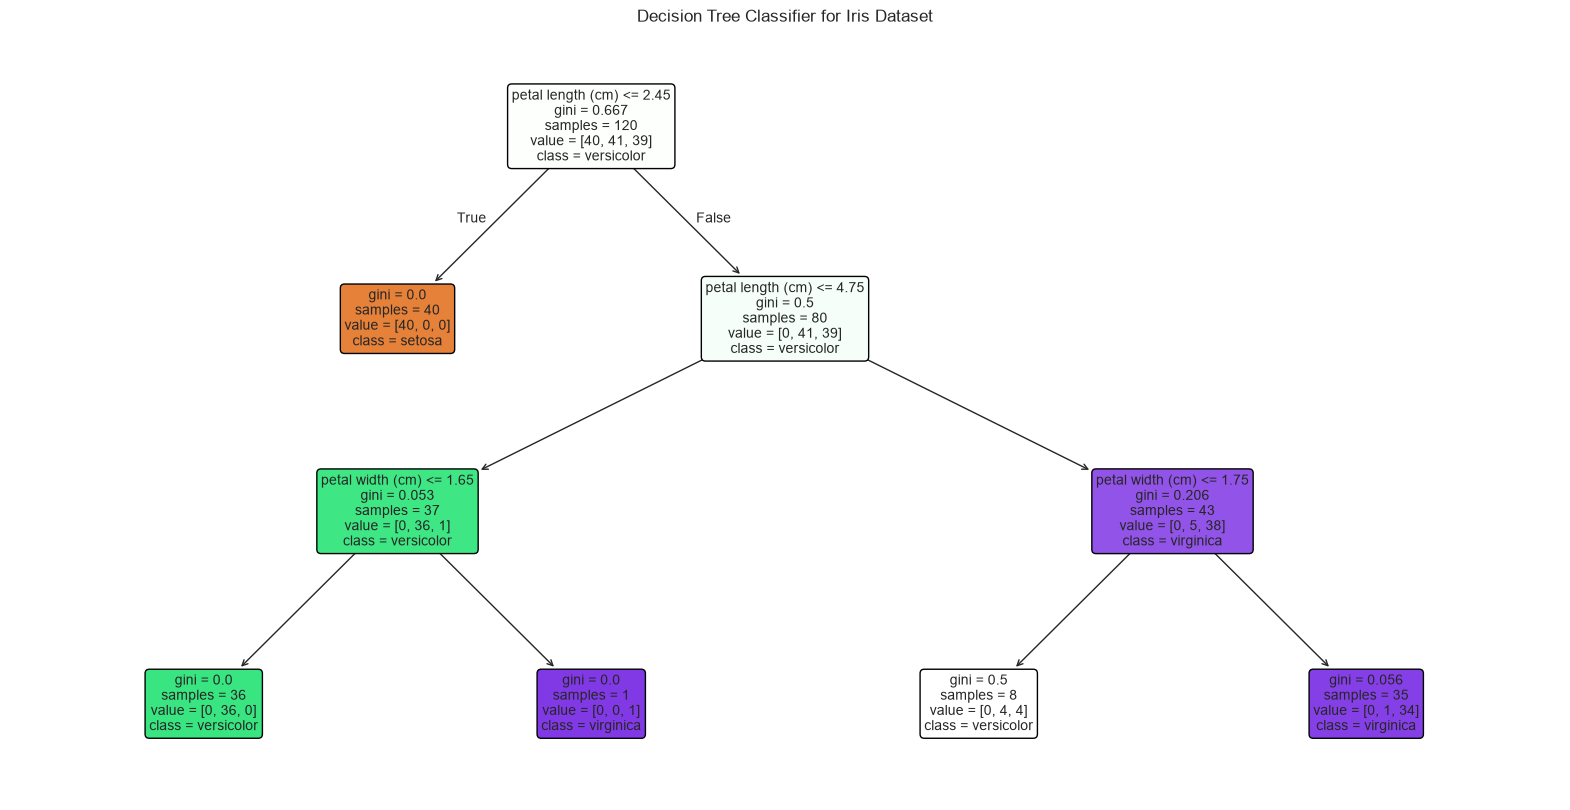


=== Feature Importance ===
             Feature  Importance
2  petal length (cm)    0.934626
3   petal width (cm)    0.065374
1   sepal width (cm)    0.000000
0  sepal length (cm)    0.000000


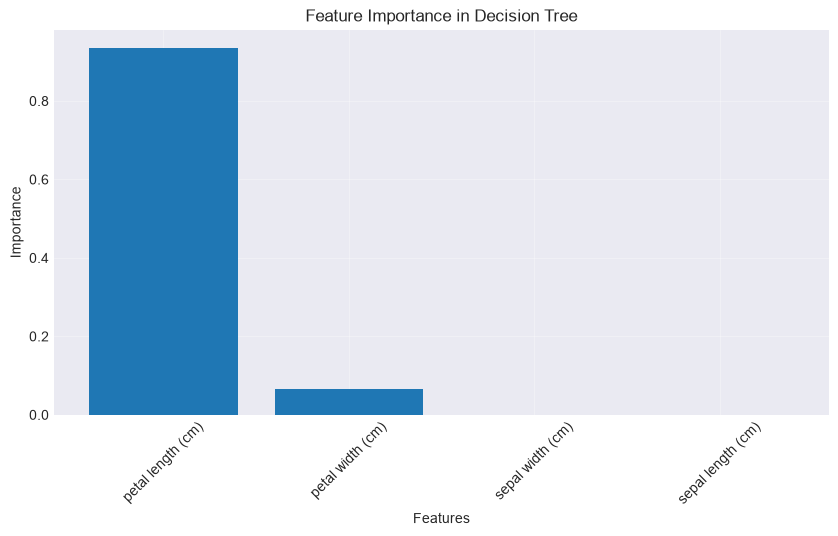

In [22]:
# Visualize the tree
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier, 
          feature_names=feature_names,
          class_names=class_names,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree Classifier for Iris Dataset')
plt.show()

# Get feature importance
importances = dt_classifier.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

print("\n=== Feature Importance ===")
print(feature_imp_df)

# Plot feature importance
plt.figure(figsize=(10, 5))
plt.bar(feature_imp_df['Feature'], feature_imp_df['Importance'])
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Feature Importance in Decision Tree')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

## 6. Understanding Tree Splitting: Step-by-Step

In [23]:
def manual_gini_split(X, y, feature_idx, threshold):
    """
    Manually split data and calculate Gini impurity
    """
    # Split data
    left_mask = X[:, feature_idx] <= threshold
    right_mask = ~left_mask
    
    y_left = y[left_mask]
    y_right = y[right_mask]
    
    if len(y_left) == 0 or len(y_right) == 0:
        return None, None
    
    # Calculate Gini for each split
    def gini(y_values):
        _, counts = np.unique(y_values, return_counts=True)
        probs = counts / len(y_values)
        return 1 - np.sum(probs**2)
    
    gini_left = gini(y_left)
    gini_right = gini(y_right)
    
    # Weighted average
    n_total = len(y)
    weighted_gini = (len(y_left)/n_total) * gini_left + (len(y_right)/n_total) * gini_right
    
    return weighted_gini, (y_left, y_right)

# Example: Splitting on petal length
feature_idx = 2  # petal length (cm)
threshold = 3.0

gini_impurity, splits = manual_gini_split(X, y, feature_idx, threshold)
print(f"Splitting on '{feature_names[feature_idx]}' at threshold {threshold}")
print(f"Weighted Gini impurity: {gini_impurity:.4f}")
if splits:
    y_left, y_right = splits
    print(f"Left split: {len(y_left)} samples")
    print(f"Right split: {len(y_right)} samples")
    print(f"Classes in left: {np.unique(y_left, return_counts=True)}")
    print(f"Classes in right: {np.unique(y_right, return_counts=True)}")

Splitting on 'petal length (cm)' at threshold 3.0
Weighted Gini impurity: 0.3430
Left split: 51 samples
Right split: 99 samples
Classes in left: (array([0, 1]), array([50,  1]))
Classes in right: (array([1, 2]), array([49, 50]))


## 7. Decision Tree for Regression

Decision trees can also be used for regression tasks.

=== Decision Tree Regressor Results ===
MSE: 1291847125.7888
RMSE: 35942.2749
R² score: 0.9800

=== Feature Importance ===
                Feature  Importance
0        Square_Footage    0.994658
3            Year_Built    0.002762
4              Lot_Size    0.001492
2         Num_Bathrooms    0.000662
1          Num_Bedrooms    0.000426
5           Garage_Size    0.000000
6  Neighborhood_Quality    0.000000


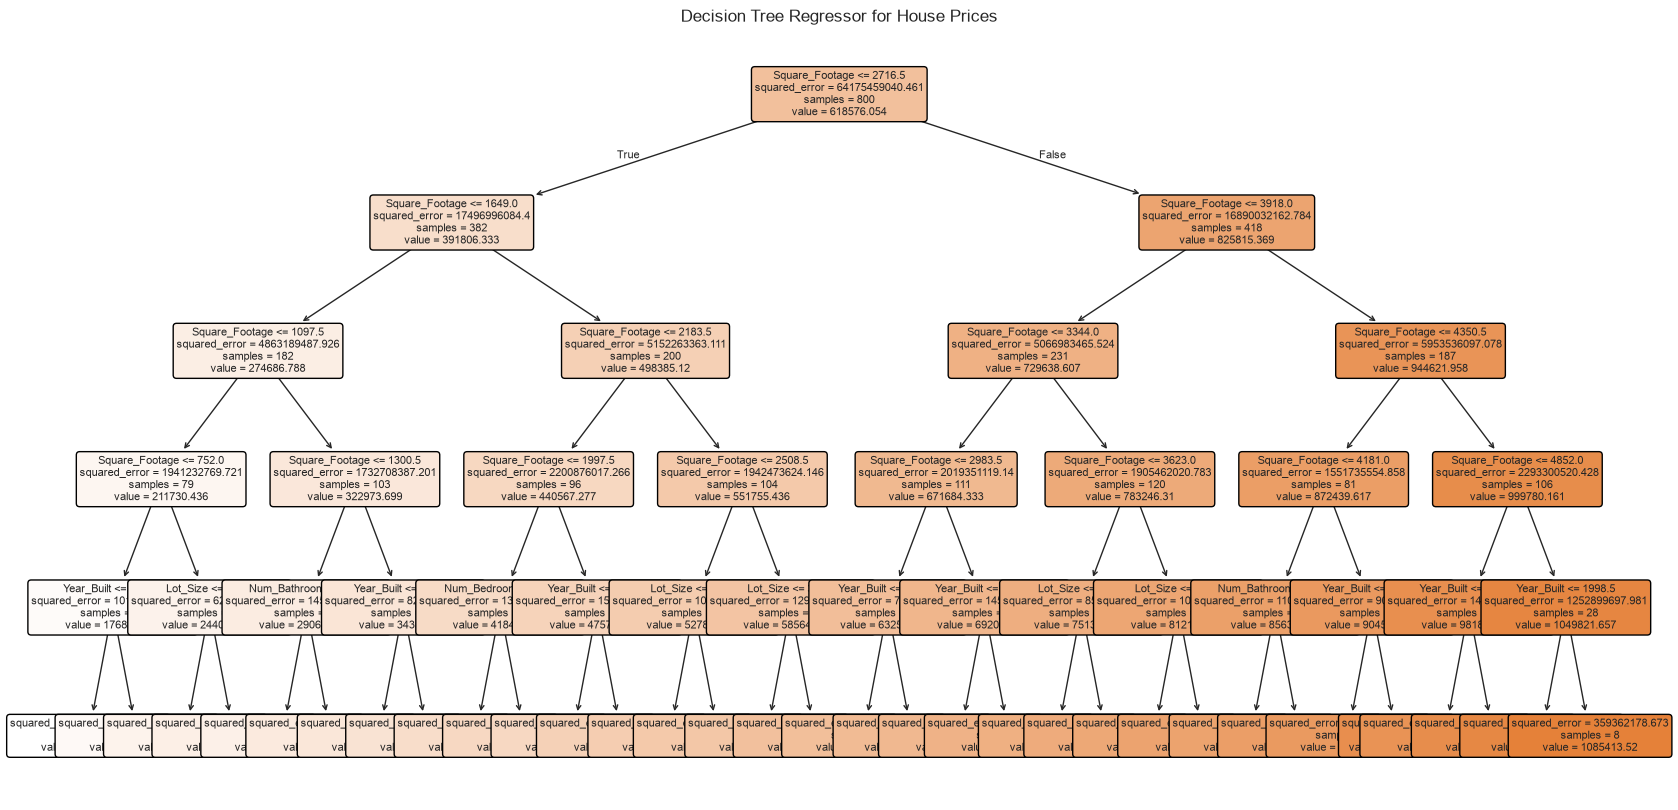

In [24]:
# Load the local house-price regression dataset
housing = pd.read_csv('house_price_regression_dataset.csv')
X_regression = housing.drop(columns='House_Price')
y_regression = housing['House_Price']
regression_feature_names = X_regression.columns.tolist()
    
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_regression, y_regression, test_size=0.2, random_state=42
)
    
# Decision tree regressor
dt_regressor = DecisionTreeRegressor(
    criterion='squared_error',
    max_depth=5,
    min_samples_split=20,
    random_state=42
)
dt_regressor.fit(X_reg_train, y_reg_train)
    
# Predictions
y_reg_pred = dt_regressor.predict(X_reg_test)
mse = mean_squared_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mse)
    
print("=== Decision Tree Regressor Results ===")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² score: {dt_regressor.score(X_reg_test, y_reg_test):.4f}")
    
# Feature importance
regression_importances = dt_regressor.feature_importances_
regression_feature_imp_df = pd.DataFrame({
    'Feature': regression_feature_names,
    'Importance': regression_importances
}).sort_values('Importance', ascending=False)
    
print("\n=== Feature Importance ===")
print(regression_feature_imp_df)
    
# Visualize regression tree
plt.figure(figsize=(20, 10))
plot_tree(dt_regressor, 
          feature_names=regression_feature_names,
          filled=True,
          rounded=True,
          fontsize=8)
plt.title('Decision Tree Regressor for House Prices')
plt.show()

## 8. Overfitting and Pruning

Decision trees are prone to overfitting if not pruned properly.

<Figure size 1200x600 with 0 Axes>

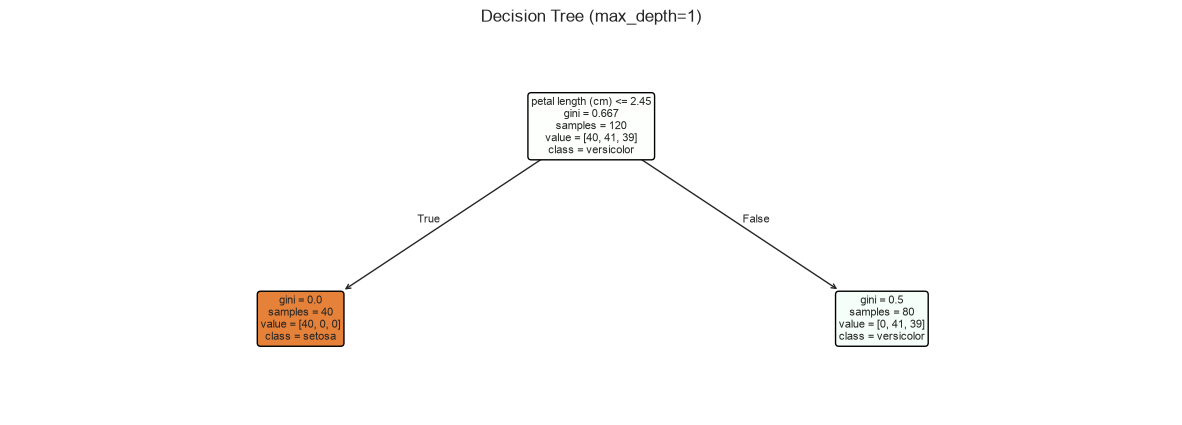

Depth 1: Train Accuracy = 0.6750, Test Accuracy = 0.6333
--------------------------------------------------


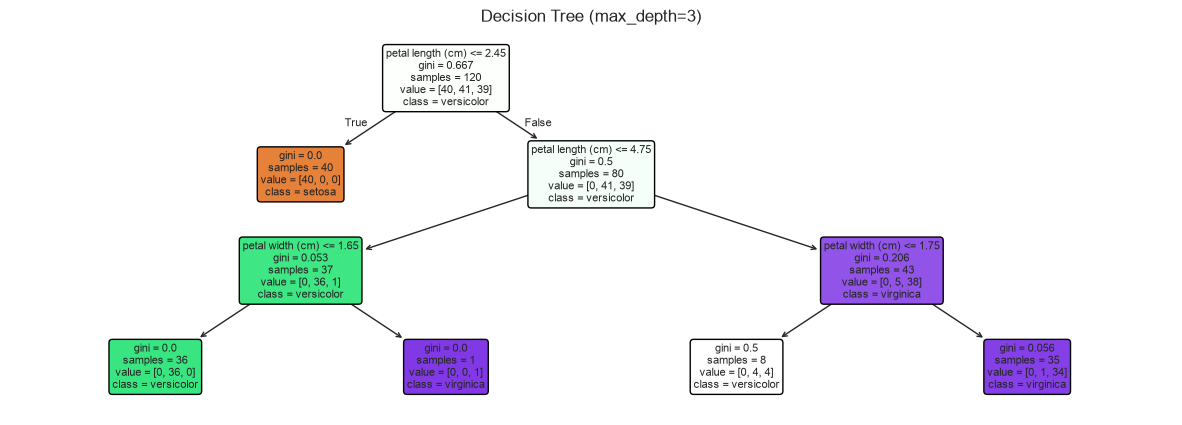

Depth 3: Train Accuracy = 0.9583, Test Accuracy = 1.0000
--------------------------------------------------


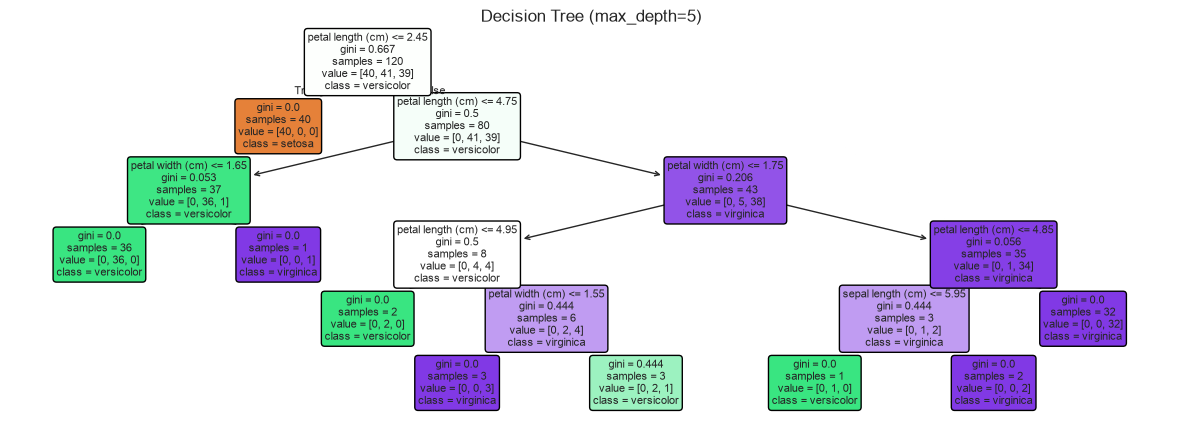

Depth 5: Train Accuracy = 0.9917, Test Accuracy = 1.0000
--------------------------------------------------


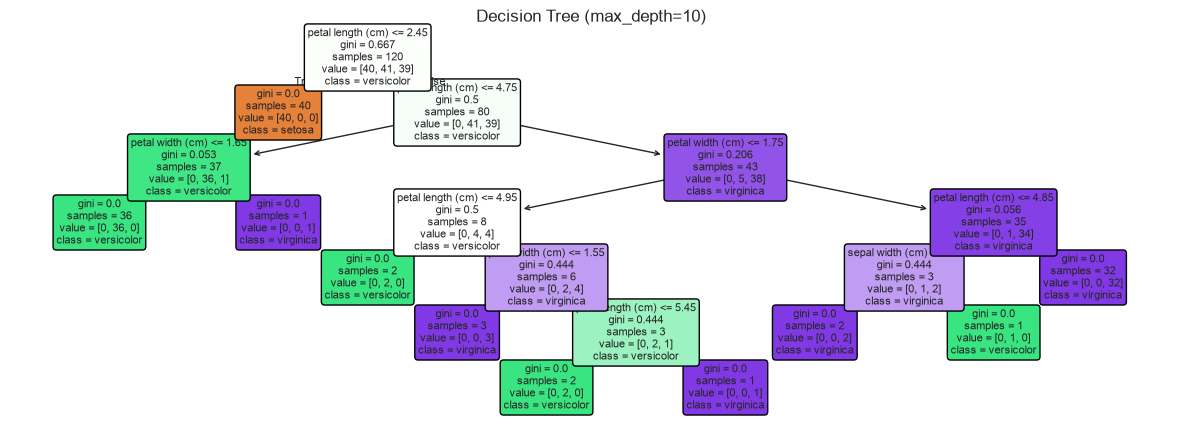

Depth 10: Train Accuracy = 1.0000, Test Accuracy = 1.0000
--------------------------------------------------


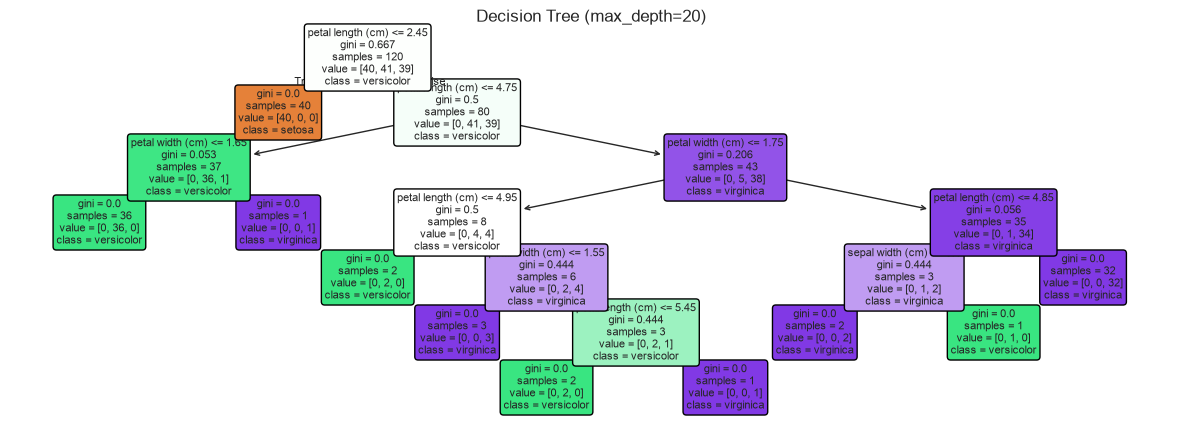

Depth 20: Train Accuracy = 1.0000, Test Accuracy = 1.0000
--------------------------------------------------


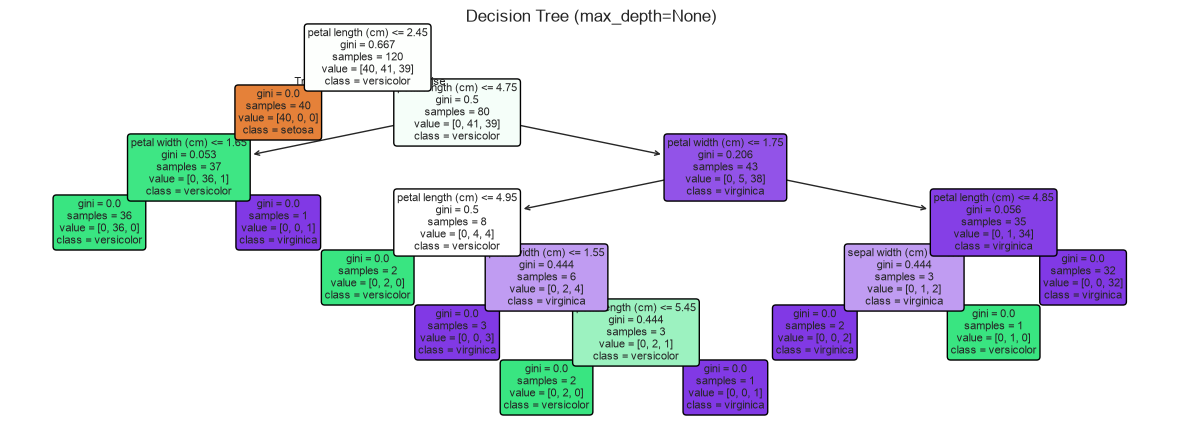

Depth None: Train Accuracy = 1.0000, Test Accuracy = 1.0000
--------------------------------------------------


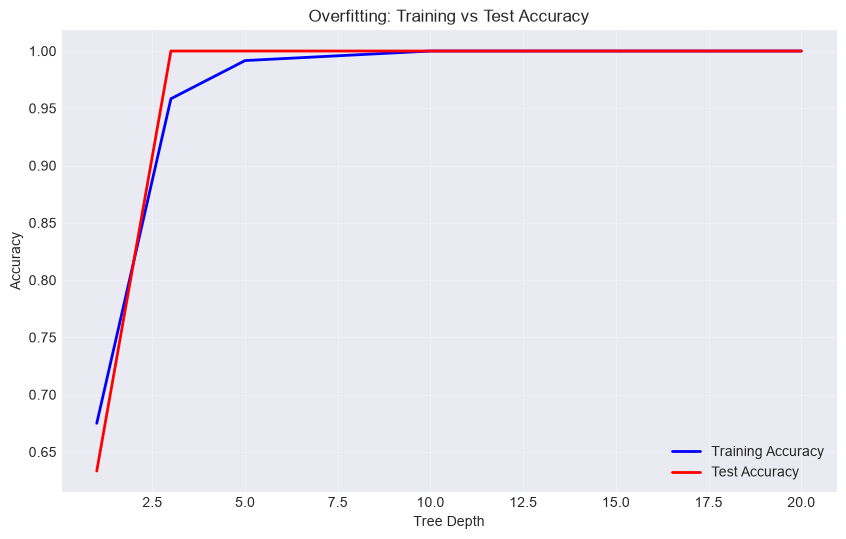

In [25]:
# Demonstrate overfitting with different depths
depths = [1, 3, 5, 10, 20, None]
train_scores = []
test_scores = []

plt.figure(figsize=(12, 6))

for depth in depths:
    # Train tree with current depth
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    
    # Calculate scores
    train_score = tree.score(X_train, y_train)
    test_score = tree.score(X_test, y_test)
    train_scores.append(train_score)
    test_scores.append(test_score)
    
    # Plot tree structure
    plt.figure(figsize=(15, 5))
    plot_tree(tree, feature_names=feature_names, class_names=class_names,
              filled=True, rounded=True, fontsize=8)
    plt.title(f'Decision Tree (max_depth={depth})')
    plt.show()
    
    print(f"Depth {depth}: Train Accuracy = {train_score:.4f}, Test Accuracy = {test_score:.4f}")
    print("-" * 50)

# Plot overfitting curve
depth_values = [1, 3, 5, 10, 20]
train_acc = [train_scores[i] for i in range(len(depths)-1)]
test_acc = [test_scores[i] for i in range(len(depths)-1)]

plt.figure(figsize=(10, 6))
plt.plot(depth_values, train_acc, 'b-', linewidth=2, label='Training Accuracy')
plt.plot(depth_values, test_acc, 'r-', linewidth=2, label='Test Accuracy')
plt.xlabel('Tree Depth')
plt.ylabel('Accuracy')
plt.title('Overfitting: Training vs Test Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 8.1 Pruning Techniques

Pruning removes branches that have little importance to prevent overfitting.

=== Pre-pruning Techniques ===
No constraint: Train=1.0000, Test=1.0000
Max depth=3: Train=0.9583, Test=1.0000
Min samples split=20: Train=0.9583, Test=1.0000
Min samples leaf=10: Train=0.9500, Test=0.9667
Max features=2: Train=1.0000, Test=1.0000

=== Cost Complexity Pruning ===


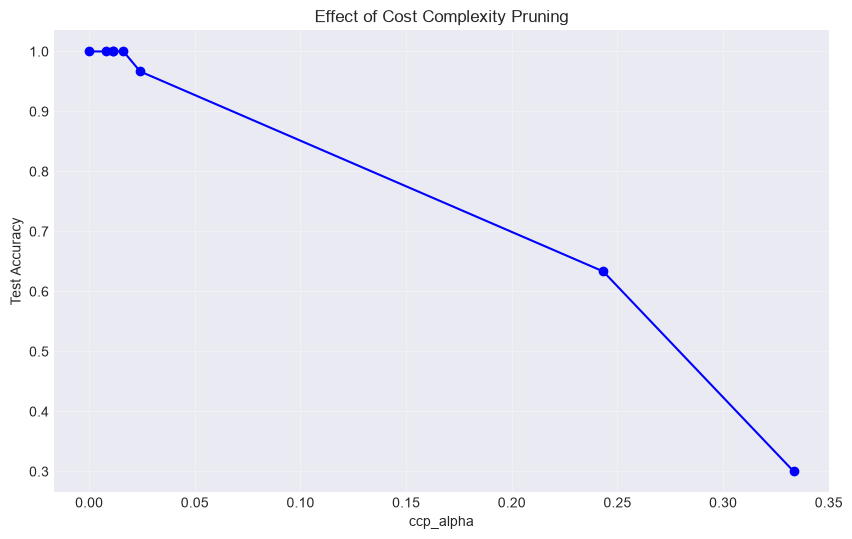

In [26]:
# Pre-pruning (limiting tree growth)
print("=== Pre-pruning Techniques ===")

# Different constraints
constraints = [
    ("No constraint", {}),
    ("Max depth=3", {'max_depth': 3}),
    ("Min samples split=20", {'min_samples_split': 20}),
    ("Min samples leaf=10", {'min_samples_leaf': 10}),
    ("Max features=2", {'max_features': 2})
]

for name, params in constraints:
    tree = DecisionTreeClassifier(random_state=42, **params)
    tree.fit(X_train, y_train)
    train_acc = tree.score(X_train, y_train)
    test_acc = tree.score(X_test, y_test)
    print(f"{name}: Train={train_acc:.4f}, Test={test_acc:.4f}")

# Post-pruning (cost complexity pruning)
print("\n=== Cost Complexity Pruning ===")

tree = DecisionTreeClassifier(random_state=42)
path = tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas
impurities = path.impurities

# Train trees with different ccp_alpha values
alpha_scores = []
for alpha in ccp_alphas[:10]:  # Test first 10 alpha values
    tree_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    tree_pruned.fit(X_train, y_train)
    test_score = tree_pruned.score(X_test, y_test)
    alpha_scores.append(test_score)

plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas[:10], alpha_scores, 'bo-')
plt.xlabel('ccp_alpha')
plt.ylabel('Test Accuracy')
plt.title('Effect of Cost Complexity Pruning')
plt.grid(True, alpha=0.3)
plt.show()

## 9. Decision Boundaries

Visualizing how decision trees partition the feature space.

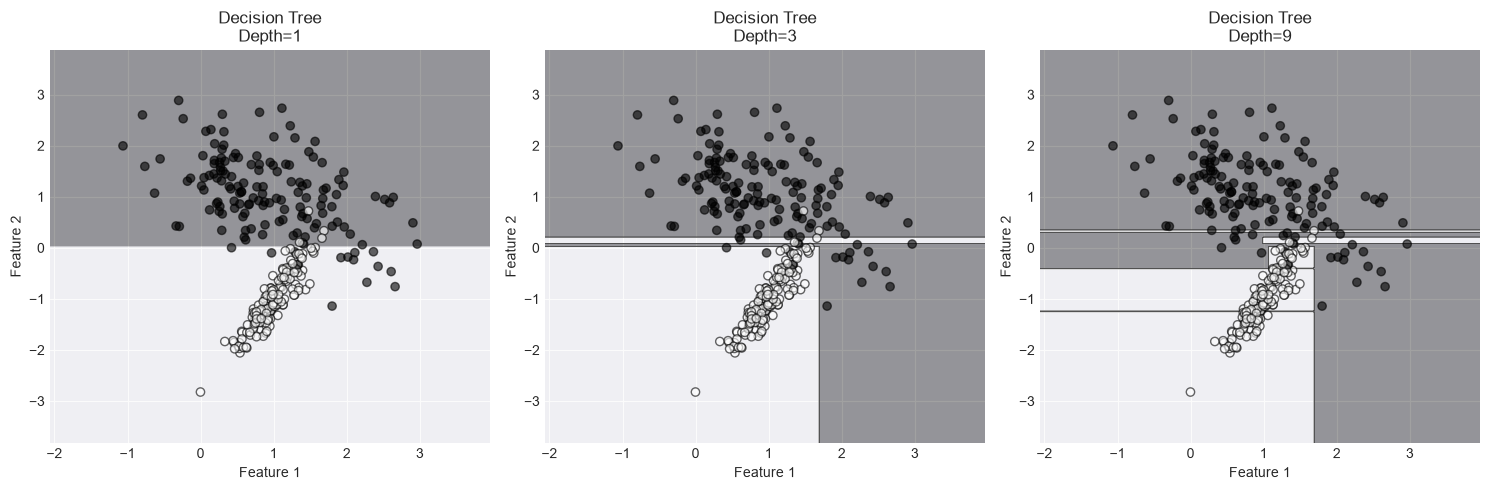

In [27]:
# Create 2D data for visualization
X_2d, y_2d = make_classification(n_samples=300, n_features=2, n_informative=2,
                                 n_redundant=0, n_clusters_per_class=1,
                                 random_state=42)

# Train trees with different depths
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
depths = [1, 3, 10]

def plot_decision_boundary(ax, X, y, tree, title):
    # Create mesh grid
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    
    # Predict on mesh
    Z = tree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plot
    ax.contourf(xx, yy, Z, alpha=0.4)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor='black', alpha=0.6)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title(f'{title}\nDepth={tree.get_depth()}')

for ax, depth in zip(axes, depths):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_2d, y_2d)
    plot_decision_boundary(ax, X_2d, y_2d, tree, 'Decision Tree')

plt.tight_layout()
plt.show()

## 10. Feature Importance Analysis

Understanding which features are most important for the decision.

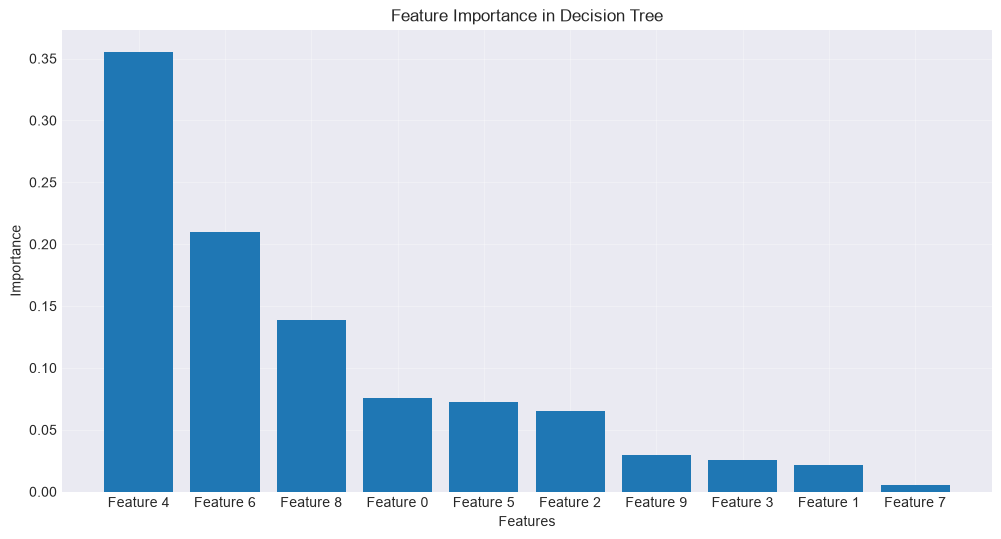

Feature Importance Ranking:
1. Feature 4: 0.3555
2. Feature 6: 0.2101
3. Feature 8: 0.1387
4. Feature 0: 0.0754
5. Feature 5: 0.0723
6. Feature 2: 0.0655
7. Feature 9: 0.0295
8. Feature 3: 0.0258
9. Feature 1: 0.0219
10. Feature 7: 0.0053


In [28]:
# Generate dataset with mixed importance
X_imp, y_imp = make_classification(n_samples=500, n_features=10,
                                   n_informative=5, n_redundant=3,
                                   random_state=42)

feature_names_imp = [f'Feature {i}' for i in range(10)]

# Train tree
tree_imp = DecisionTreeClassifier(random_state=42)
tree_imp.fit(X_imp, y_imp)

# Get feature importance
importances = tree_imp.feature_importances_

# Sort features by importance
indices = np.argsort(importances)[::-1]

# Plot
plt.figure(figsize=(12, 6))
plt.bar(range(10), importances[indices])
plt.xticks(range(10), [feature_names_imp[i] for i in indices])
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Feature Importance in Decision Tree')
plt.grid(True, alpha=0.3)
plt.show()

print("Feature Importance Ranking:")
for i, idx in enumerate(indices):
    print(f"{i+1}. {feature_names_imp[idx]}: {importances[idx]:.4f}")

## 11. Cross-Validation for Optimal Parameters

=== Best Parameters ===
{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}

Best cross-validation score: 0.9500
Test accuracy: 1.0000


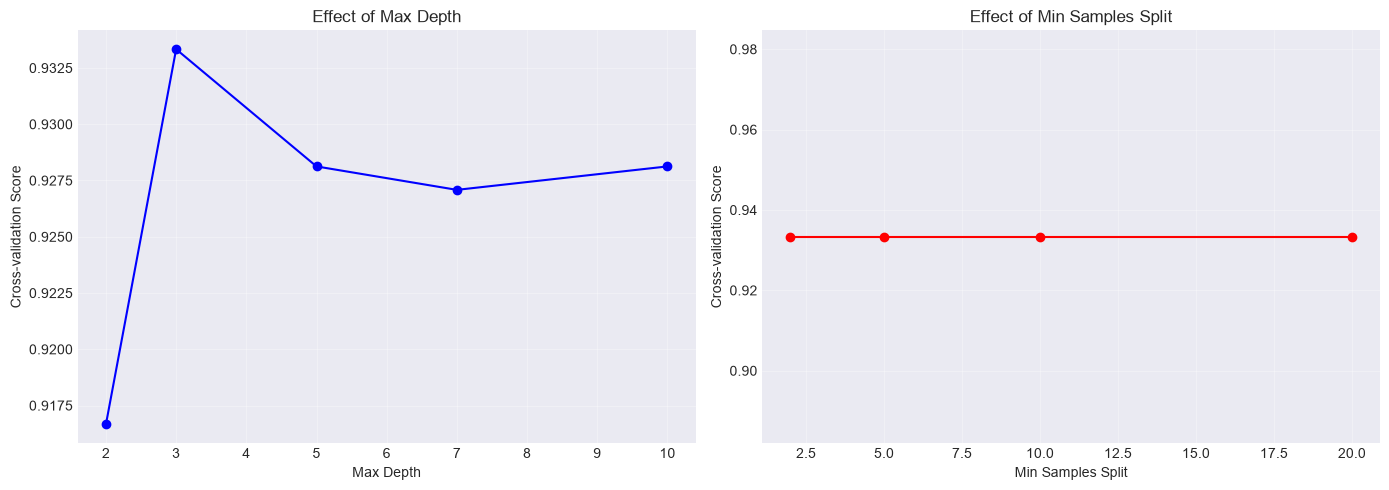

In [29]:
from sklearn.model_selection import GridSearchCV

# Parameter grid for tuning
param_grid = {
    'max_depth': [2, 3, 5, 7, 10],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# Grid search
tree_grid = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(tree_grid, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("=== Best Parameters ===")
print(grid_search.best_params_)
print(f"\nBest cross-validation score: {grid_search.best_score_:.4f}")
print(f"Test accuracy: {grid_search.score(X_test, y_test):.4f}")

# Results visualization
results = pd.DataFrame(grid_search.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Effect of max_depth
depth_results = results[results['param_min_samples_split'] == 2].groupby('param_max_depth')['mean_test_score'].mean()
axes[0].plot(depth_results.index, depth_results.values, 'bo-')
axes[0].set_xlabel('Max Depth')
axes[0].set_ylabel('Cross-validation Score')
axes[0].set_title('Effect of Max Depth')
axes[0].grid(True, alpha=0.3)

# Effect of min_samples_split
split_results = results[results['param_max_depth'] == 3].groupby('param_min_samples_split')['mean_test_score'].mean()
axes[1].plot(split_results.index, split_results.values, 'ro-')
axes[1].set_xlabel('Min Samples Split')
axes[1].set_ylabel('Cross-validation Score')
axes[1].set_title('Effect of Min Samples Split')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Comparison with Other Algorithms

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

# Compare multiple models
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42)
}

results_comparison = {}

for name, model in models.items():
    # Cross-validation scores
    cv_scores = cross_val_score(model, X_train, y_train, cv=5)
    # Fit and test score
    model.fit(X_train, y_train)
    test_score = model.score(X_test, y_test)
    results_comparison[name] = {
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std(),
        'Test Score': test_score
    }

# Display results
comparison_df = pd.DataFrame(results_comparison).T
print("=== Model Comparison ===")
print(comparison_df)

=== Model Comparison ===
                      CV Mean    CV Std  Test Score
Decision Tree        0.933333  0.056519         1.0
Random Forest        0.941667  0.056519         1.0
KNN                  0.941667  0.056519         1.0
SVM                  0.950000  0.061237         1.0
Logistic Regression  0.966667  0.048591         1.0


## 13. Advantages and Disadvantages

### Advantages of Decision Trees:

1. **Interpretability**: Easy to understand and explain
2. **Versatility**: Can handle both classification and regression
3. **No assumptions**: Non-parametric, no distribution assumptions
4. **Handles mixed data**: Both numerical and categorical features
5. **Non-linear relationships**: Captures non-linear patterns
6. **Feature importance**: Built-in feature ranking
7. **Scalable**: Works well with large datasets

### Disadvantages of Decision Trees:

1. **Overfitting**: Prone to overfitting without pruning
2. **Instability**: Small changes in data can lead to different trees
3. **Bias**: Biased towards features with more levels
4. **Non-optimal**: May not find the globally optimal tree
5. **Continuous features**: Less effective for continuous features
6. **Outlier sensitivity**: Sensitive to outliers

### Best Practices:

1. **Prune the tree**: Use pre-pruning or post-pruning
2. **Limit depth**: Set max_depth to prevent overfitting
3. **Ensemble methods**: Use Random Forest or Gradient Boosting
4. **Feature scaling**: Not necessary but can help
5. **Cross-validation**: Always validate parameters
6. **Handle imbalance**: Use class_weight parameter

## 14. Summary and Key Takeaways

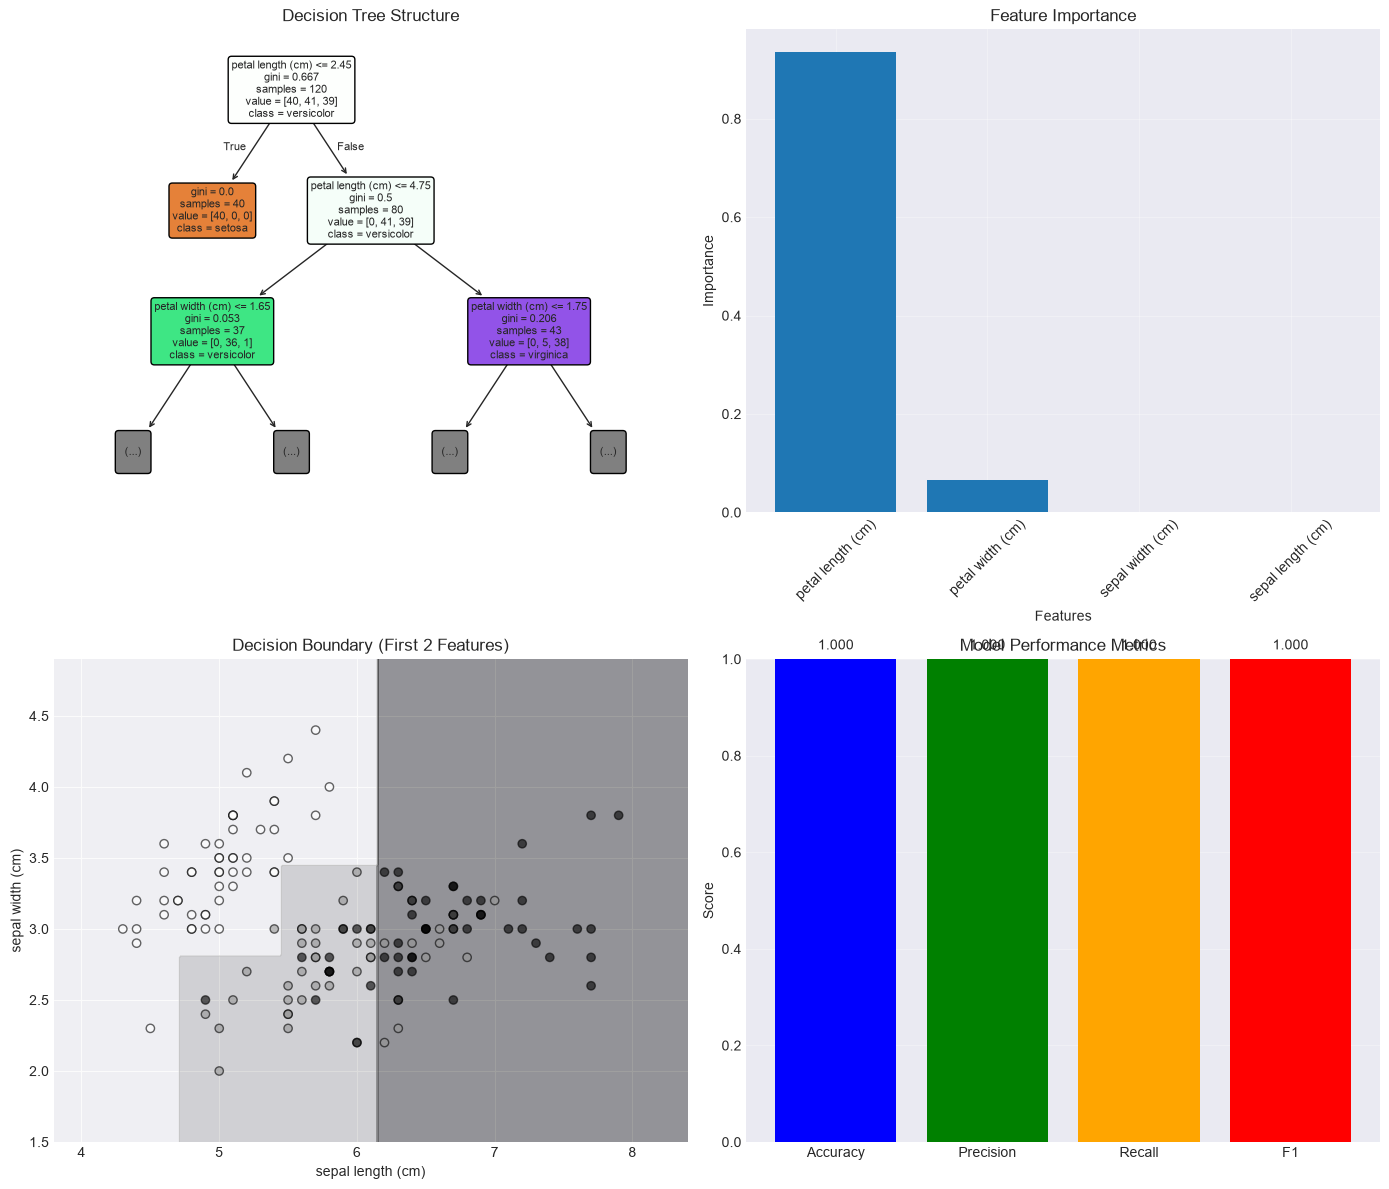

In [31]:
# Summary visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 1. Tree structure
ax1 = axes[0, 0]
plot_tree(dt_classifier, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, ax=ax1, fontsize=8, max_depth=2)
ax1.set_title('Decision Tree Structure', fontsize=12)

# 2. Feature importance
ax2 = axes[0, 1]
ax2.bar(feature_imp_df['Feature'], feature_imp_df['Importance'])
ax2.set_xlabel('Features')
ax2.set_ylabel('Importance')
ax2.set_title('Feature Importance')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, alpha=0.3)

# 3. Decision boundary (simplified)
ax3 = axes[1, 0]
# Use first two features for visualization
X_vis = X[:, :2]
tree_vis = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_vis.fit(X_vis, y)

x_min, x_max = X_vis[:, 0].min() - 0.5, X_vis[:, 0].max() + 0.5
y_min, y_max = X_vis[:, 1].min() - 0.5, X_vis[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))
Z = tree_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
ax3.contourf(xx, yy, Z, alpha=0.4)
ax3.scatter(X_vis[:, 0], X_vis[:, 1], c=y, edgecolor='black', alpha=0.6)
ax3.set_xlabel(feature_names[0])
ax3.set_ylabel(feature_names[1])
ax3.set_title('Decision Boundary (First 2 Features)')

# 4. Performance metrics
ax4 = axes[1, 1]
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
from sklearn.metrics import precision_score, recall_score, f1_score
values = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, average='weighted'),
    recall_score(y_test, y_pred, average='weighted'),
    f1_score(y_test, y_pred, average='weighted')
]
ax4.bar(metrics, values, color=['blue', 'green', 'orange', 'red'])
ax4.set_ylabel('Score')
ax4.set_title('Model Performance Metrics')
ax4.set_ylim(0, 1)
ax4.grid(True, alpha=0.3)

for i, v in enumerate(values):
    ax4.text(i, v + 0.02, f'{v:.3f}', ha='center')

plt.tight_layout()
plt.show()

## Final Summary

### Key Concepts Covered:

1. **Tree Structure**: Root → Internal → Leaf nodes
2. **Splitting Criteria**: Gini impurity, Entropy, Information Gain
3. **Building Trees**: Recursive binary splitting
4. **Classification**: Class labels at leaf nodes
5. **Regression**: Continuous values at leaf nodes
6. **Pruning**: Pre-pruning and post-pruning
7. **Feature Importance**: Built-in ranking
8. **Decision Boundaries**: Rectangular regions in feature space

### When to Use Decision Trees:

✅ **Good for**:
- Explainable predictions
- Quick baseline models
- Non-linear relationships
- Mixed data types

❌ **Avoid for**:
- Complex relationships (use ensemble methods)
- High-dimensional data
- Online learning
- When stability is critical